# 99.7b Spatial Discretization

## Contents

**Tools:** CADET-Python; convergence and sharp-front explorer widgets; loading reference data; refinement and plotting helpers.

**Python used:** Imports, lists and dictionaries, keyword arguments, helper calls and widget display.

**Introduces:** Finite volumes (FV), discontinuous Galerkin (DG), WENO reconstruction, polynomial degree, experimental order of convergence (EOC), and balanced axial and particle resolution.

1. FV and DG solutions of concentration profiles
2. Accuracy and runtime in a load-wash-elute example
3. Grid refinement and experimental convergence order
4. Sharp fronts: WENO reconstruction and DG oscillations
5. Competitive Langmuir binding and self-sharpening fronts
6. General rate models: balancing axial and particle discretization

Spatial discretization affects both the accuracy and computational cost of a simulation. In this lesson, we compare FV and DG methods, investigate how they handle smooth profiles and sharp fronts, and explore how spatial refinement influences accuracy and runtime. Finally, we examine how to balance the resolution between the column and the particles in more complex models.

## Spatial Discretization Methods

There are two spatial discretization methods implemented in CADET-Core: **Discontinuous Galerkin (DG)** and **Finite Volumes (FV)**. 

- **Finite Volumes (FV):** Divides the spatial domain into cells and represents the solution using cell averages. Higher-order accuracy can be achieved using reconstruction schemes such as **Weighted Essentially Non-Oscillatory (WENO)**.
- **Discontinous Galerkin (DG):** Divides the spatial domain into elements and represents the solution using polynomials of degree $p$ within each element.

The choice of discretization method, spatial resolution and polynomial degree affects both **accuracy** and **runtime** of the simulation. For further details, see [<u>CADET spatial discretization documentation</u>](https://cadet.github.io/master/interface/spatial_discretization_methods.html).

![approximation_FV_vs_DG.png](attachment:b95b8318-e1b0-4e77-aa57-cf5f52ede820.png)

<details>
<summary><b>Click for more details</b></summary>

![approximation_FV_DG_orders.png](attachment:ec744460-7a5e-4d31-8b7f-e42612c3bca7.png)
![approximation_WENO_vs_DG.png](attachment:97858f10-a79b-41d4-9f86-b8bbd774bb3e.png)


## <span style="color: red;"> **Important Note:**</span>
Throughout this notebook, the time discretization error was fixed so that the spatial discretization error always dominates. That way, we can investigate spatial discretization separately.

Combining the insights of this notebook and the [time discretization notebook](02_time_discretization.ipynb), **spatial and temporal** discretization parameters should be **selected to achieve similar accuracy**.
Otherwise, the **larger error dominates** and the computational requirements of the other discretizations attempted lower error renders the **simulation inefficient**.

### Example: Lumped Rate Model with Pores

We start with a **load-wash-elute example** with three components and a salt, modeled by a [<u>Lumped Rate Model with Pores</u>](https://cadet.github.io/v5.1.X/modelling/unit_operations/lumped_rate_model_with_pores.html) with [<u>Steric Mass-Action Binding</u>](https://cadet.github.io/v5.1.X/modelling/binding/steric_mass_action.html#steric-mass-action-model).
The particle of an LRMP holds a single, lumped concentration rather than a resolved profile, so there is **no particle discretization to choose**: the axial direction carries the whole spatial error.

**Error vs wall clock time:**

The error is computed over all components $k$ and time points $t_i$ as the absolute discrete $L^\infty$ error

$$
e = \max_{i,k} \left|c_k(t_i) - c_{k,\mathrm{ref}}(t_i)\right|,
$$

Plotting that error against the compute time shows which method is computationally superior:
**the superior method reaches a given accuracy fastest**


In [1]:
from IPython.display import display

import utility.cadet_runtime as cadet_runtime
from utility.convergence_explorer import convergence_explorer

# Only needed to rerun a level; the published results load without CADET.
cadet_runtime.configure()

lrmp_explorer = convergence_explorer('lrmp_sma')
display(lrmp_explorer)

### Key takeaway: DG can be more efficient by 1-2 orders of magnitude

## Convergence order

What drives the efficiency of numerical methods for smooth settings (i.e. solutions without discontinuous or steep concentration profiles), is the theoretical convergence order of the method.
The experimental order of convergence (EOC) is computed by
$$
\mathrm{EOC} = 
\frac{\log\left(\dfrac{e_{n-1}}{e_n}\right)}
{\log\left(\dfrac{N_n}{N_{n-1}}\right)},
$$
where $e_n$ is the maximum outlet error for refinement $n$, and $N_n$ is the axial resolution. Positive EOC indicates decreasing error.\
For FV: $N_n$ is the number of axial cells.\
For DG: $N_n$ is the number of axial elements. At fixed polynomial degree, using $(p+1)N_n$ gives the same EOC.

## Convergence Study Example:

Consider a **single-component Lumped Rate Model (LRM)** with **linear adsorption**. A concentration pulse is injected for $10 \mathrm{s}$, and the resulting outlet concentration profile is simulated.

To investigate spatial convergence, we progressively refine the axial discretization while keeping the physical and solver parameters fixed.


The numerical solutions are compared against the CASEMA reference solution using the discrete absolute $L^\infty$ error:

$$
e_n = \max_i \left|c_n(t_i)-c_{\mathrm{CASEMA}}(t_i)\right|,
$$

evaluated at the reference output times without normalization. The experimental order of convergence (EOC) is calculated between consecutive spatial refinements.

Observe:
- How **quickly** does the error decrease with increasing spatial resolution?
- How do the experimental convergence orders **compare** between FV and DG?
- Does a higher polynomial degree always lead to better **computational efficiency**?

Method Cells/elements   L-infinity error        EOC    Runtime [s]
------------------------------------------------------------------
    FV              4       3.312289e-01          -      3.296e-02
    FV              8       2.081428e-01      0.670      4.496e-02
    FV             16       8.485670e-02      1.294      6.174e-02
    FV             32       2.375372e-02      1.837      9.132e-02
    FV             64       5.510106e-03      2.108      1.482e-01
    FV            128       1.086142e-03      2.343      2.720e-01
    FV            256       1.843745e-04      2.559      5.837e-01
    FV            512       3.075224e-05      2.584      1.223e+00
------------------------------------------------------------------
   DG1              4       2.492051e-01          -      1.444e-02
   DG1              8       1.585073e-01      0.653      2.550e-02
   DG1             16       7.633095e-02      1.054      6.037e-02
   DG1             32       2.681362e-02      1.509      9.771

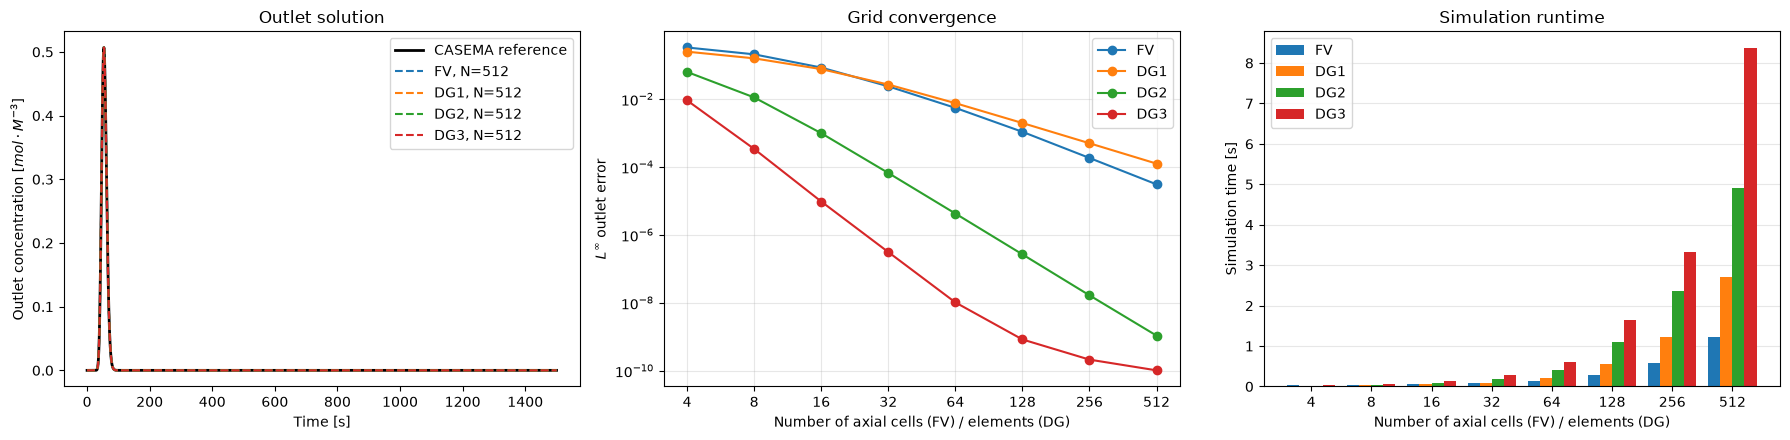

In [2]:
from pathlib import Path

from utility.spatial_convergence import (
    load_reference,
    run_refinement_study,
    plot_refinement_study,
    print_max_slopes,
)

# Configure the Cadet runtime and set up the data directory for the reference data
cadet_runtime.configure()
data_directory = Path('data') / '01_spatial_discretization'
reference_file = (data_directory / 'reference'
                  / 'LRM_dynLin_1comp_benchmark1.h5')

# One run per method and grid is written here while the study is
# refined; the published figure needs none of them afterwards.
refinement_directory = data_directory / 'refinement'
refinement_directory.mkdir(parents=True, exist_ok=True)

# Define the axial cell counts and the numerical methods to be used in the study
axial_cell_counts = [4, 8, 16, 32, 64, 128, 256, 512]
methods = {'FV': 0, 'DG1': 1, 'DG2': 2, 'DG3': 3}

# Load the reference solution and run the spatial refinement study
reference = load_reference(reference_file)
results = run_refinement_study(reference, axial_cell_counts, methods,
                               refinement_directory)
fig = plot_refinement_study(reference, axial_cell_counts, results)

In [3]:
# Print the maximum slopes for the convergence study
print_max_slopes(axial_cell_counts, results)


Maximum decay slopes (most negative log-log slopes):
FV: -2.584 (256->512)
DG1: -1.992 (256->512)
DG2: -4.007 (128->256)
DG3: -5.142 (8->16)


## Why does CADET have FV then? -> Spatial stabilization !

- DG is a linear high order ($EOC>1$) method and thus generally allows new extrema
- Controlling these extrema requires a nonlinear mechanism like the **WENO FV reconstruction**
- DG is only advantageous if the solution is smooth enough, which to our experience is **usually** the case

### But when does DG show this bad behaviour ?
**Sharp concentration fronts** are challenging for numerical methods. Low-order schemes often introduce **numerical diffusion**, smoothing sharp fronts, while higher-order schemes may produce **spurious oscillations** near steep gradients.  


<details>
<summary><b>Click for details on WENO</b></summary>
The **FV Weighted Essentially Non-Oscillatory (WENO)** scheme addresses the high-order loworder trade-off by combining several reconstruction stencils using smoothness-dependent weights. This allows high-order accuracy in smooth regions while reducing oscillations near sharp gradients. 

CADET provides three WENO reconstruction settings for FV method,controlled by `WENO_ORDER`:

| `WENO_ORDER` | Stencil size | Order of accuracy |Typical behavior |
|---|---|---|---|
| **1** | 1 cell (first-order upwind) | 1st |  Robust, but introduces substantial numerical diffusion |
| **2** | 2-cell stencils | 3rd (2nd order at boundaries) | Sharper fronts, reduced numerical diffusion |
| **3** | 3-cell stencils | 5th (2nd order at boundaries) | Higher accuracy in smooth regions, potentially sharper fronts |


Increasing the reconstruction order can improve the resolution of sharp concentration fronts, but may also increase computational cost. Further reading: [<u>Jiang & Shu (1996), Efficient Implementation of Weighted ENO Schemes.</u>](https://doi.org/10.1006/jcph.1996.0130)

Let's investigate how these schemes behave when transporting sharp concentration fronts through a column.

### Key takeaway: DG struggles with strong gradients, FV can be more efficient here

### WENO Example: Sharp Fronts and Pulses

Consider a $0.1 \mathrm{m}$ column without adsorption or particles, initially filled with pure solvent. A solute is introduced at the inlet and transported through the column by convection.

**What happens when axial dispersion is very small?**

With little physical smoothing, sharp concentration changes remain steep as they travel through the column. The numerical method must therefore capture these fronts without introducing excessive smearing or artificial oscillations.

We investigate two scenarios:

**1. Step input:** A constant concentration of $1,\mathrm{mol/m^3}$ is introduced, creating a single advancing front.

**2. Pulse input:** The solute is injected for $60,\mathrm{s}$, followed by pure solvent, creating both leading and trailing fronts.

Compare WENO1, WENO2, and WENO3 using the same axial degrees of freedom and dispersion coefficient:

- Run the simulations and compare the concentration profiles.
- Observe how sharply each scheme captures the fronts.
- Look for numerical diffusion and possible undershoots or overshoots.
- Change the spatial resolution and dispersion coefficient. How does the behavior change?

**Reference:** The dashed black curve represents ideal transport without dispersion **$(D=0)$**, where the inlet signal is simply delayed by the column residence time:

$$
\tau = \frac{L}{u} \approx 88.1,\mathrm{s},
\qquad
c_{\mathrm{out}}(t) = c_{\mathrm{in}}(t-\tau).
$$

**Numerical behavior:** The concentration should remain between $0$ and $1,\mathrm{mol/m^3}$. Values outside this range indicate numerical **undershoot** or **overshoot**, while excessive smoothing may indicate **numerical diffusion**.

In [5]:
import importlib
from IPython.display import display
from utility.sharp_front_comparison import sharp_gradient_explorer

# Set up the WENO methods
weno_methods = [('FV', 1), ('FV', 2), ('FV', 3)]

# Run two studies for the WENO methods
weno_explorer = sharp_gradient_explorer(
    mode='both',
    output_directory=Path('data') / '01_spatial_discretization' / 'rerun',
    methods=weno_methods,
)
display(weno_explorer)


### Discontinous Galerkin 

Unlike the finite volume (FV) method, which represents the solution using cell averages and reconstructs values at cell interfaces, the **Discontinuous Galerkin (DG)** method approximates the solution using polynomials within each element. The polynomial degree $p$ controls the approximation order.

Higher polynomial degrees can provide greater accuracy for smooth solutions. However, near sharp concentration fronts or discontinuities, polynomial approximations may produce **spurious oscillations**. This occurs because a finite-degree polynomial cannot represent a discontinuity within an element exactly, and its approximation is not necessarily bounded by the minimum and maximum values of the solution. This behavior is related to the **Gibbs phenomenon**.

Let's investigate this behavior by comparing **DG** with **FV (WENO3)** for the same sharp-front and pulse examples.

### DG Example: Sharp Fronts and Pulses

Let's revisit the previous examples using the same column and inlet conditions.

Compare **DG**, **FV (WENO3)**, and the ideal advection reference $(D=0)$:
- Look for numerical overshoots and undershoots. Do you observe any **oscillations**? 
- How do the oscillations behave with respect to changing **dispersion coefficient**, **polynomial degree** and **resolution**?
- Does increasing the polynomial degree always improve the solution? 
- How does **DG** compare with **FV (WENO3)** in terms of accuracy, oscillations, and computational cost?

In [6]:
# Set up the DG methods for the comparison
dg_methods = [('FV', 3),
              ('DG', 1), ('DG', 2), ('DG', 3), ('DG', 4), ('DG', 5)]

# Run the DG methods comparison study
dg_explorer = sharp_gradient_explorer(
    mode='both',
    output_directory=Path('data') / '01_spatial_discretization' / 'rerun',
    methods=dg_methods,
)
display(dg_explorer)


### Key-takeaway: With enough dispersion, there are no strong gradients
Dispersion comes from
- axial dispersion coefficient
- film diffusion kinetics
- pore diffusion kinetics
- binding kinetics

### Does it ever happen then in an actual setting?

### Example: Competitive Langmuir with steep concentration fronts

The same comparison for a **two-component [<u>Langmuir</u>](https://cadet.github.io/v5.1.X/modelling/binding/multi_component_langmuir.html) setting** in a [<u>Lumped Rate Model</u>](https://cadet.github.io/v5.1.X/modelling/unit_operations/lumped_rate_model_without_pores.html), with little axial dispersion. The solution develops **self-sharpening concentration fronts**, and the convergence plot looks nothing like the smooth case from before:

In [3]:
from IPython.display import display

import utility.cadet_runtime as cadet_runtime
from utility.convergence_explorer import convergence_explorer

cadet_runtime.configure()

langmuir_explorer = convergence_explorer('lrm_langmuir')
display(langmuir_explorer)


## Spatial discretization of multiple domains

### Example: General Rate Model

The [<u>General Rate Model</u>](https://cadet.github.io/v5.1.X/modelling/unit_operations/general_rate_model.html) introduced the particle spatial domain, which also needs to be discretized.
The following example is again a load-wash-elute simulation with [<u>Steric Mass-Action Binding</u>](https://cadet.github.io/v5.1.X/modelling/binding/steric_mass_action.html#steric-mass-action-model).
The particle is now resolved, so there is a **second discretization to choose**.

In [4]:
from pathlib import Path

from IPython.display import display

import utility.cadet_runtime as cadet_runtime
from utility.lwe_discretization_explorer import lwe_discretization_explorer

# Only needed to rerun a setting; the stored results load without CADET.
cadet_runtime.configure()

# Every setting on the sliders was simulated beforehand with
# utility/make_lwe_discretization_results.py, at abstol 1E-12 and reltol 1E-10,
# so that what you see is the spatial discretization error. The explorer loads
# those results instantly; switch the mode to "Rerun simulation" to run the
# selected setting through CADET yourself and time it on this machine.
discretization_explorer = lwe_discretization_explorer(
    store=(Path('data') / '01_spatial_discretization'
           / 'lwe_discretization'),
    output_directory=Path('data') / '01_spatial_discretization' / 'rerun',
)
display(discretization_explorer)


### Key-takeaway: Axial and particle discretization must be in balance

Note: DG and FV can also be mixed, i.e., one for the bulk and one for the particles

## References
- **Original WENO FV CADET code**: [Eric von Lieres and Joel Andersson. A fast and accurate solver for the general rate model of column liquid chromatography. 2010.](https://doi.org/10.1016/j.compchemeng.2010.03.008)
- **First DG implementation in chromatography**: [Kristian Meyer, Samuel Leweke, and Eric von Lieres, Jakob K. Huusom, Jens Abildskov. ChromaTech: A discontinuous Galerkin spectral element simulator for preparative liquid chromatography. 2020.](https://doi.org/10.1016/j.compchemeng.2026.109928)
- **CADET DG implementation and first investigation on oscillations**: [Jan Michael Breuer, Samuel Leweke, Johannes Schmölder, Gregor Gassner, and Eric von Lieres. Spatial discontinuous galerkin spectral element method for a family of chromatography models in CADET. 2023.](https://doi.org/10.1016/j.compchemeng.2023.108340)

## Summary

- Compare spatial methods using both error and runtime; the most accurate method is not necessarily the most efficient one.
- DG can be efficient for smooth profiles, while sharp fronts can introduce oscillations and require careful selection of the spatial discretization method.
- Balance axial and particle resolution.

**Next lesson:** [**99.7c Time Discretization**](99.7c_time_discretization_lesson.ipynb) explores implicit time integration, the influence of error tolerances on accuracy and runtime, and the structure of the Jacobian matrix.